This Jupyter notebook describes how to use pyBIS to implement the example from the tutorial “Uploading Data to the openBIS Data Store – Lab Notebook.”
https://bamresearch.github.io/openBIS-data-store-tutorials/lab-notebook/


Important Libraries

In [ ]:
%pip install pybis
%pip install requests
%pip install zipfile
%pip install ipykernel
%pip install jupyterlab

In [ ]:
from helper import *#helper functions for this notebook

### To log in using a session token,

1. Log in to the Bam Data Store website 
2. Go to the Tools tab on the top left
3. Select User Profile from the list of options provided
4. Copy the OpenBIS session token and use it in the next cell.

In [ ]:
from pybis import Openbis
o = Openbis("https://playground.datastore.bam.de/")

o.set_token("narshad-261019154043695xFDDB1ADE98B882E44A837F474942963A")
#user_token_here

Download Datasets for future use.

In [ ]:
import os
import requests

urls =  ["https://bamresearch.github.io/openBIS-data-store-tutorials/lab-notebook/datasets/Parameter1_Macroscopic.zip", 
         "https://bamresearch.github.io/openBIS-data-store-tutorials/lab-notebook/datasets/datasets.zip"]

folder = "datasets"
filenames = ["Parameter1_Macroscopic.zip", "datasets.zip"]

os.makedirs(folder, exist_ok=True)

for i in range(2):
    filepath = os.path.join(folder, filenames[i])
    response = requests.get(urls[i], stream=True)
    response.raise_for_status()

    with open(filepath, "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            if chunk:
                f.write(chunk)

    print(f"Saved file to {filepath}")

### The next cell is used to extract the zip file called datasets.zip

In [ ]:
import zipfile

zip_path = "datasets/datasets.zip"
extract_dir = "datasets"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print(f"Extracted {zip_path} to {extract_dir}")

os.remove("datasets/datasets.zip")#removes the zipped version of the file which we do not need anymore

In [ ]:
# print(o.get_spaces())#please uncomment this line and execute it to see all the spaces and find the code for yours in the table displayed

myspace = o.get_space('VP.1_NARSHAD')#input your space's code here to save it in the myspace variable
#fix this to your space code
#fix this to your space code
#fix this to your space code
#fix this to your space code
#fix this to your space code
#fix this to your space code

In [ ]:
myspace.attrs.all()#run to see your space's attributes.

### Step 1: Register a Project called 'Material Synthesis'.


We first display all the projects and their indices currently in your space

### Ask Angela and Caroline if this stays and also search collections/samples too.


### The function 'search_projects': 
- Searches projects by a given keyword (for example: 'material' would return 'Material Synthesis')
- returns indices and project names

Use the keyword 'all' to return all the projects in the space

### Note: In case there is a change of the session token, the search_projects function will not work properly unless you load the myspace variable again into the notebook



In [ ]:
myspace.get_projects()#to see current projects in the space
# search_projects(myspace,'all')# all is there because once they add projects/collections/samples they can see the changes in the parent entity

In [ ]:
project = myspace.new_project(
    code        = 'pybis_new_test',#This is the name of the project
    description = 'This tutorial project demonstrates a simplified workflow for the synthesis and characterization of a material within openBIS. The experimental descriptions, metadata, and datasets were generated using AI and represent synthetic example data created solely for training and demonstration purposes. Although the content has been reviewed for consistency and usability within the tutorial, it has not been validated for scientific accuracy and should not be considered scientifically reliable or reproducible.'
)
project#has not been registered yet, need to call project.save() to save it to the openBIS server

In [ ]:
project.save()#this will save the project into the space you set in myspace

In [14]:
myspace.get_projects()#as you can see, a new project has been registered

,permId,identifier,code,description,frozen,frozenForExperiments,frozenForSamples,registrationDate,modificationDate,registrator,modifier,leader
0,20260730141307558-7843,/VP.1_NARSHAD/MATERIAL_SYNTHESIS_SEARCH_VERSION,MATERIAL_SYNTHESIS_SEARCH_VERSION,This tutorial project demonstrates a simplifie...,False,False,False,2026-07-30 14:13:08,2026-07-30 14:13:08,narshad,narshad,
1,20260805145021695-7990,/VP.1_NARSHAD/MATERIAL_SYNTHESIS_3,MATERIAL_SYNTHESIS_3,This tutorial project demonstrates a simplifie...,False,False,False,2026-08-05 14:50:22,2026-08-05 14:52:46,narshad,narshad,
2,20260706121842133-7227,/VP.1_NARSHAD/PYBIS_MATERIAL_SYNTHESIS,PYBIS_MATERIAL_SYNTHESIS,This tutorial project demonstrates a simplifie...,False,False,False,2026-07-06 12:18:42,2026-10-13 14:43:02,narshad,narshad,
3,20260805163930634-8006,/VP.1_NARSHAD/MATERIAL_SYNTHESIS_2,MATERIAL_SYNTHESIS_2,This tutorial project demonstrates a simplifie...,False,False,False,2026-08-05 16:39:31,2026-08-05 16:49:52,narshad,narshad,
4,20261019155549461-16433,/VP.1_NARSHAD/PYBIS_NEW_TEST,PYBIS_NEW_TEST,This tutorial project demonstrates a simplifie...,False,False,False,2026-10-19 15:55:49,2026-10-19 15:55:49,narshad,narshad,
5,20260806142530360-8022,/VP.1_NARSHAD/PARSER_TEST,PARSER_TEST,NaN,False,False,False,2026-08-06 14:25:30,2026-10-11 19:43:46,narshad,narshad,
6,20260908140327284-8874,/VP.1_NARSHAD/PYBIS_INVENTORY_USERS_TUTORIAL,PYBIS_INVENTORY_USERS_TUTORIAL,NaN,False,False,False,2026-09-08 14:03:27,2026-09-21 14:45:10,narshad,narshad,
7,20260731150349352-7908,/VP.1_NARSHAD/MATERIAL_SYNTHESISS,MATERIAL_SYNTHESISS,This tutorial project demonstrates a simplifie...,False,False,False,2026-07-31 15:03:49,2026-07-31 15:10:20,narshad,narshad,
8,20260701125327592-7155,/VP.1_NARSHAD/MATERIAL_SYNTHESIS,MATERIAL_SYNTHESIS,<p>This tutorial project demonstrates a simpli...,False,False,False,2026-07-01 12:53:28,2026-07-06 15:01:58,narshad,narshad,
9,20260702112339526-7182,/VP.1_NARSHAD/QUERIES,QUERIES,Generated by ELN for stored search queries.,False,False,False,2026-07-02 11:23:40,2026-07-02 11:23:40,narshad,narshad,


In [ ]:
myspace.get_projects(code='pybis_new_test')#as you can see, a new project has been registered
# search_projects(myspace,'pybis')#searching for the project we just created

,permId,identifier,code,description,frozen,frozenForExperiments,frozenForSamples,registrationDate,modificationDate,registrator,modifier,leader
0,20261019155549461-16433,/VP.1_NARSHAD/PYBIS_NEW_TEST,PYBIS_NEW_TEST,This tutorial project demonstrates a simplifie...,False,False,False,2026-10-19 15:55:49,2026-10-19 15:55:49,narshad,narshad,


In [ ]:
project.attrs.all()#this displays all the attributes of the project

{'code': 'PYBIS_NEW_TEST',
 'permId': '20261019155549461-16433',
 'identifier': '/VP.1_NARSHAD/PYBIS_NEW_TEST',
 'space': 'VP.1_NARSHAD',
 'description': 'This tutorial project demonstrates a simplified workflow for the synthesis and characterization of a material within openBIS. The experimental descriptions, metadata, and datasets were generated using AI and represent synthetic example data created solely for training and demonstration purposes. Although the content has been reviewed for consistency and usability within the tutorial, it has not been validated for scientific accuracy and should not be considered scientifically reliable or reproducible.',
 'leader': None,
 'registrator': 'narshad',
 'registrationDate': '2026-10-19 15:55:49',
 'modifier': '13',
 'modificationDate': '2026-10-19 15:55:49',
 'frozen': False,
 'frozenForExperiments': False,
 'frozenForSamples': False}

### Note: Properties vs Attributes
Do projects have only attributes not properties?

In [19]:
project.props.all()#shows an error so yes, projects only have attributes in pybis

AttributeError: 'NoneType' object has no attribute 'codes'

In [ ]:
#in case you have already created the project and want to save it into a variable because you have closed the notebook and reopened it, 
# you can use this line to get the project we just created and save it in the variable project

# project= myspace.get_project('Material_Synthesis')

### Step 2: Register Collections of Experimental Steps

We will be creating and registering a collection called 'Synthesis' under the project that you just registered.



### The function 'search_collections': 
- Searches collections by a given keyword (for example: 'param' would return Parameter 1 and Parameter 2)
- returns indices and collection names

Use the keyword 'all' to return all the collections in the project

### Note: In case there is a change of the session token, the search_collections function will not work properly unless you load myspace, and project variables again into the notebook

In [20]:
project.get_collections()#As you have not yet registered any collections yet, this will return an empty list
search_collections(project, 'all')

'Error: There are no collections in the project.'

In [ ]:
col = o.new_collection(
    code = auto_generated_code(project), #the 'auto_generated_code' function will generate a new code for the collection based on the number of collections already in the project
    type='Collection',#this specifies that the new entity is of the type 'collection'.
    project= project.identifier,#project.identifier is the unique identifier for the project called material synthesis that was created in step 1 and in which this new collection will be registered. 
    props = {'$name': 'Synthesis'}#Enter the name of the Collection here.
)
col

attribute,value
code,PYBIS_NEW_TEST_EXP_1
type,COLLECTION
project,/VP.1_NARSHAD/PYBIS_NEW_TEST
tags,[]


In [22]:
col.save()#to save the collection in the project you created

experiment successfully created.


attribute,value
code,PYBIS_NEW_TEST_EXP_1
permId,20261019161143872-16434
identifier,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_1
type,COLLECTION
project,/VP.1_NARSHAD/PYBIS_NEW_TEST
tags,[]
registrator,narshad
registrationDate,2026-10-19 16:11:44
modifier,narshad
modificationDate,2026-10-19 16:11:44


In [23]:
# project.get_collections()#You will see the collection you just saved.
search_collections(project, 'all')

Indices		Collections
0		Synthesis


### Registering additional collections

We will now create additional collections by reusing the same knowledge we applied in step 2.

The names for the collections are: Treatment non-destructive, Structure_TEM, Parameter 1, and Parameter 2

In [24]:
collection_names = ["Treatment non-destructive","Structure_TEM","Parameter 1","Parameter 2"]#names of the collections to register

for name in collection_names:
    collection = o.new_collection(
        code=auto_generated_code(project),#code is autogenerated for each collection
        type='Collection',
        project= project.identifier,
        props = {'$name': name}
    )
    collection.save()
    print(f"Created collection: {name}")

project.get_collections()

experiment successfully created.
Created collection: Treatment non-destructive
experiment successfully created.
Created collection: Structure_TEM
experiment successfully created.
Created collection: Parameter 1
experiment successfully created.
Created collection: Parameter 2


,permId,identifier,registrationDate,modificationDate,type,registrator,modifier
0,20261019161143872-16434,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_1,2026-10-19 16:11:44,2026-10-19 16:11:44,COLLECTION,narshad,narshad
1,20261019161151519-16435,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_2,2026-10-19 16:11:52,2026-10-19 16:11:52,COLLECTION,narshad,narshad
2,20261019161151941-16436,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_3,2026-10-19 16:11:52,2026-10-19 16:11:52,COLLECTION,narshad,narshad
3,20261019161152385-16437,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_4,2026-10-19 16:11:52,2026-10-19 16:11:52,COLLECTION,narshad,narshad
4,20261019161152744-16438,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_5,2026-10-19 16:11:53,2026-10-19 16:11:53,COLLECTION,narshad,narshad


In [25]:
# project.get_collections()#You will see the collection you just saved.
search_collections(project, 'all')

Indices		Collections
0		Synthesis
1		Treatment non-destructive
2		Structure_TEM
3		Parameter 1
4		Parameter 2


### Step 3 : Register Experimental Steps using Templates
Experimental Steps may require extensive metadata to fully describe the datasets generated. To standardize this information and simplify the registration of similar Experimental Steps, reusable templates can be created and shared within a division. Templates are particurly useful for repetitive workflows in which experimental conditions remain the same or require minor modifications. They help ensure consistency, reduce manual data entry, and improve the efficiency of experimental documentation.


We will now register an Experimental Step using a previously defined Template that allows reusability and fills out a lot of metadata fields for the experiment.

In [26]:
manual_template_sample = o.new_sample(
    type       = 'EXPERIMENTAL_STEP',
    collection =  col,
    props      =  {'$name': 'Manual Material Synthesis',
                    '$show_in_project_overview': True,
                    'finished_flag': False,
                    'start_date': None,
                    'end_date': None,
                    'experimental_step.experimental_goals': '<p>To synthesize and process functional materials with controlled composition, structure, and properties using a reproducible and parameterized workflow suitable for a wide range of material classes (e.g., powders, thin films, composites, nanomaterials).</p>',
                    'experimental_step.experimental_description': '<p>Template for documenting generic material synthesis procedures, including precursor preparation, reaction processing, post-treatment, and intermediate/ final material handling.</p><h4><strong>Safety Precautions</strong></h4><ul><li>Wear appropriate PPE (lab coat, gloves, safety goggles).</li><li>Handle chemicals according to MSDS guidelines.</li><li>Use fume hood for volatile, toxic, or reactive substances.</li><li>Ensure proper handling of high-temperature equipment and pressurized systems.</li><li>Dispose of waste according to institutional and regulatory requirements.</li></ul><h4><strong>Synthesis Workflow</strong></h4><h4><strong>1. Precursor Preparation</strong></h4><ol><li>Define target material composition and stoichiometry.</li><li>Select precursor materials (e.g., salts, powders, polymers, solvents).</li><li>Weigh and record all precursor masses.</li><li>Dissolve or disperse precursors in appropriate solvent(s).</li><li>Adjust concentration and pH if required.</li><li>Apply mixing method:<ul><li>Magnetic stirring / overhead stirring</li><li>Ultrasonication</li><li>Ball milling</li></ul></li></ol><h4><strong>2. Reaction / Synthesis Step</strong></h4><ol><li>Transfer precursor solution or mixture into reaction vessel.</li><li>Set synthesis conditions:<ul><li>Temperature: ___ °C</li><li>Pressure: ___ bar (if applicable)</li><li>Atmosphere: air / inert / reactive gas</li></ul></li><li>Initiate reaction using selected method:<ul><li>Thermal treatment</li><li>Hydrothermal / solvothermal synthesis</li><li>Chemical precipitation</li><li>Vapor deposition / coating</li></ul></li><li>Maintain reaction for defined duration: ___ min/h</li><li>Monitor process (optional):<ul><li>pH</li><li>Temperature profile</li><li>Gas evolution</li><li>Optical/visual changes</li></ul></li></ol><h4><strong>3. Material Recovery</strong></h4><ol><li>Separate product phase:<ul><li>Filtration / centrifugation / decantation</li></ul></li><li>Wash material using appropriate solvent(s).</li><li>Repeat washing cycles until impurities are minimized (record number of cycles).</li><li>Dry material under defined conditions:<ul><li>Air drying / vacuum drying / freeze drying</li><li>Temperature: ___ °C</li><li>Duration: ___ h</li></ul></li></ol><h4><strong>4. Post-Treatment / Processing</strong></h4><ol><li>Apply additional processing if required:<ul><li>Calcination / annealing</li><li>Sintering</li><li>Mechanical processing (grinding, milling, pressing)</li></ul></li><li>Define treatment conditions:<ul><li>Temperature profile</li><li>Heating rate</li><li>Atmosphere</li></ul></li><li>Cool material under controlled conditions.</li></ol><h4><strong>5. Functionalization / Modification (Optional)</strong></h4><ol><li>Introduce dopants, coatings, or surface modifications.</li><li>Repeat reaction and recovery steps if applicable.</li><li>Record concentrations and incorporation method.</li></ol><h4><strong>6. Sample Preparation for Characterization</strong></h4><ol><li>Prepare material for analysis:<ul><li>Pelletizing / coating / dispersion</li></ul></li><li>Assign sample identifiers.</li><li>Store samples under defined conditions.</li></ol><h4><strong>Experimental Parameters (Key Variables)</strong></h4><ul><li>Composition ratios</li><li>Precursor concentration</li><li>Solvent type</li><li>Reaction temperature and time</li><li>pH</li><li>Atmosphere</li><li>Post-treatment temperature and duration</li></ul><p>&nbsp;</p>',
                    'experimental_step.experimental_results': '<figure class="table"><table><thead><tr><th>Sample ID</th><th>Composition</th><th>Process Conditions</th><th>Yield [%]</th><th>Notes</th></tr></thead><tbody><tr><td>Sample-1</td><td>&nbsp;</td><td>&nbsp;</td><td>&nbsp;</td><td>&nbsp;</td></tr><tr><td>Sample-2</td><td>&nbsp;</td><td>&nbsp;</td><td>&nbsp;</td><td>&nbsp;</td></tr></tbody></table></figure>',
                    'experimental_step.spreadsheet': None,
                    'reference': '<ul><li>Literature references for synthesis routes</li><li>Internal protocols / SOPs</li></ul>',
                    'publication': None,
                    'notes': '<p>Free text for additional notes, optimization insights, or anomalies.</p>',
                    '$xmlcomments': None}
)
manual_template_sample

attribute,value
code,
type,EXPERIMENTAL_STEP
project,/VP.1_NARSHAD/PYBIS_NEW_TEST
parents,[]
children,[]
container,
components,[]
space,VP.1_NARSHAD
experiment,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_1
tags,[]


In [27]:
manual_template_sample.save()#save this into the data store
# ask JR, object is created properly but an error is shown in pybis output.

sample successfully created.


In [28]:
template_sample = o.new_sample(
    type       = 'EXPERIMENTAL_STEP',
    collection =  col,
    props      =  templates['Material Synthesis']#templates are defined in the helper.py file
)
template_sample

attribute,value
code,
type,EXPERIMENTAL_STEP
project,/VP.1_NARSHAD/PYBIS_NEW_TEST
parents,[]
children,[]
container,
components,[]
space,VP.1_NARSHAD
experiment,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_1
tags,[]


In [29]:
template_sample.save()#save this into the data store
# ask JR, object is created properly but an error is shown in pybis output.

sample successfully created.


AttributeError: 'str' object has no attribute '_set_data'

### The function 'search_samples': 
- Searches samples by a given keyword (for example: 'material' would return Material Demo 001 and Material Synthesis)
- returns indices and collection names

Use the keyword 'all' to return all the samples in the collection

### Note: In case there is a change of the session token, the search_samples function will not work properly unless you load myspace, project, and collection variables again into the notebook

Upon executing the next cell, you should see in the following output cells and in the openBIS instance (GUI-graphical user interface) that there are now two Experimental Steps registered under 'Synthesis':
- Material Demo 001 (created in step 3)
- Material Synthesis (created in step 4)

In [30]:
col.get_objects()#To retrieve and display the objects within the collection.
search_samples(col,'all')

Indices		Samples
0		Manual Material Synthesis
1		Material Synthesis


### Step 4: Edit Collections and Objects (Experimental Steps)


To learn how to edit collections, we will be renaming the collection 'Structure TEM' to 'Parameter 2 Analysis' 

Since there are multiple collections in our Project, we will use the `search_collections()` function to facilitate the work with collections.

In [31]:
# make it auto assign structure tem

for x in project.get_collections():
    print(x.props.all())

# search_collections(project,'structure')

{'$name': 'Synthesis', '$default_object_type': None, '$default_collection_view': None}
{'$name': 'Treatment non-destructive', '$default_object_type': None, '$default_collection_view': None}
{'$name': 'Structure_TEM', '$default_object_type': None, '$default_collection_view': None}
{'$name': 'Parameter 1', '$default_object_type': None, '$default_collection_view': None}
{'$name': 'Parameter 2', '$default_object_type': None, '$default_collection_view': None}


In [32]:
#To rename the Experimental Step 'Structure_TEM', we save it in the variable exp_to_rename. 
exp_to_rename = next(collection for index, collection in enumerate(project.get_collections()) if collection.props['$name'] == 'Structure_TEM')
exp_to_rename.props.all()

{'$name': 'Structure_TEM',
 '$default_object_type': None,
 '$default_collection_view': None}

In [33]:
exp_to_rename.props['$name'] = 'Parameter 2 Analysis'#To set the '$name' property of the exp_to_rename variable to 'Parameter 2 Analysis', which is the new name we want to assign to the Experimental Step.

In [34]:
exp_to_rename.save()#To save the changes made to the exp_to_rename variable, we call the save() method. This will update the properties of the Experimental Step in the data store.

experiment successfully updated.


attribute,value
code,PYBIS_NEW_TEST_EXP_3
permId,20261019161151941-16436
identifier,/VP.1_NARSHAD/PYBIS_NEW_TEST/PYBIS_NEW_TEST_EXP_3
type,COLLECTION
project,/VP.1_NARSHAD/PYBIS_NEW_TEST
tags,[]
registrator,narshad
registrationDate,2026-10-19 16:11:52
modifier,narshad
modificationDate,2026-10-19 16:22:01


In [35]:
exp_to_rename.props.all()#run this to check if the change is applied locally

{'$name': 'Parameter 2 Analysis',
 '$default_object_type': None,
 '$default_collection_view': None}

### ASK ANGELA AND CAROLINE, NOW THAT WE'VE ADDED A SAMPLE USING TEMPLATES CALLED MANUAL MATERIAL SYNTHESIS, SHOULD WE SHOW THAT HERE AND REMOVE THAT???

### Deletion of objects

To learn how to delete objects, we will delete the object called 'Material Demo 001'

In [ ]:
# #remove for pybis workshop 
# # synthesis_col = next(collection for index, collection in enumerate(project.get_collections()) if collection.props['$name'] == 'Synthesis')
# synthesis_col.props.all()

In [ ]:
# #remove for pybis workshop 
# # col.get_samples()#To retrieve and display the samples/objects within the collection 'Synthesis'. This will show the two experiments currently registered in the collection.
# search_samples(col, 'all')

In [ ]:
# #remove for pybis workshop 
# #To select the sample/object to be deleted, we save it in the variable sample_to_be_deleted.
# sample_to_be_deleted = next(sample for index, sample in enumerate(col.get_samples()) if sample.props['$name'] == 'Material Demo 001')
# sample_to_be_deleted.props.all()

In [ ]:
#remove for pybis workshop 
#sample_to_be_deleted.delete('Add reason here for deletion')

In [ ]:
# #remove for pybis workshop 
# #col.get_samples()#To retrieve and display the samples/objects within the collection 'Synthesis' after deletion. This will show only one experiment remaining in the collection.
# search_samples(col, 'all')

### Step 5: Register additional Experimental Steps using Templates

As described in Step 3, you will now create five additional Experimental Steps using predefined templates. These Experimental Steps will be required to complete the remaining exercises in this tutorial.

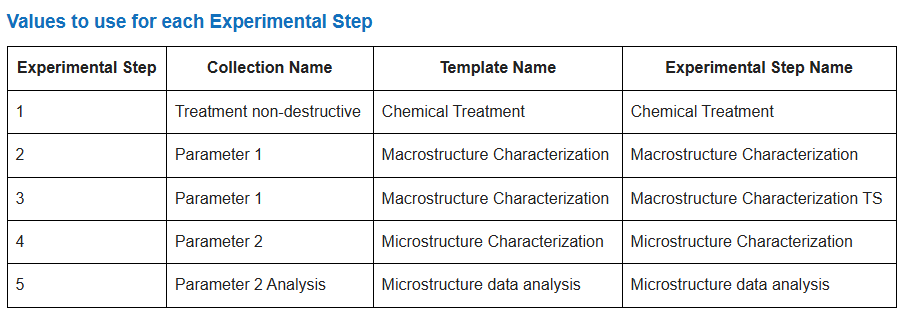

### MAKE A LOOP FOR REGISTERING ADDITIONAL TEMPLATES

In [43]:
template_dict = {'Treatment non-destructive' : 'Chemical Treatment',
                 'Parameter 1' : 'Macrostructure Characterization',#add macro ts
                 'Parameter 2' : 'Microstructure Characterization',
                 'Parameter 2 Analysis' : 'Microstructure data analysis'}


for collection_name, template_name in template_dict.items():
    template_sample = o.new_sample(
    type       = 'EXPERIMENTAL_STEP',
    collection =  next(collection for index, collection in enumerate(project.get_collections()) if collection.props['$name'] == collection_name),
    props      =  templates[template_name]
    )
    template_sample.save()

    if collection_name == 'Parameter 1':
        macro_ts_template = templates['Macrostructure Characterization'].copy()#made a copy so that it doesnt edit the actual template for Macrostructure Characterization
        macro_ts_template['$name'] = 'Macrostructure Characterization TS'

        template_sample = o.new_sample(
            type       = 'EXPERIMENTAL_STEP',
            collection =  next(collection for index, collection in enumerate(project.get_collections()) if collection.props['$name'] == collection_name),
            props      =  macro_ts_template
            )
        template_sample.save()

sample successfully created.
sample successfully created.
sample successfully created.
sample successfully created.
sample successfully created.


### Step 7: Upload Data

The Data Store recommends to attach datasets directly to Experimental Steps that describe how the data was generated. In openBIS, uploaded files are stored as Datasets. Because openBIS is format-agnostic, datasets can contain files of any type or format.

You will now upload a dataset (Parameter1_Macroscopic.zip) of type Raw Data to the Experimental Step called 'Macrostructure Characterization' organized within the collection 'Parameter 1'. You will also add some comments with the dataset.

You already downloaded the datasets required for this step at the beginning. They are saved in your local folder along with this Jupyter notebook.

In [ ]:
search_collections(project,'parameter 1')#To retrieve and display the collections within the project that match the search term 'parameter 1'. 

col = next(collection for index, collection in enumerate(project.get_collections()) if collection.props['$name'] == 'Parameter 1')
col.props.all()

In [ ]:
#We need to find the index of the Experimental Step 'Macrostructure Characterization'.
# for x in col.get_samples():
#     print(x.props.all())
search_samples(col,'all')

In [ ]:
#To select the sample/object to be deleted, we save it in the variable sample_to_be_deleted.
sample = next(sample for index, sample in enumerate(col.get_samples()) if sample.props['$name'] == 'Macrostructure Characterization')
sample.props.all()

In [ ]:
#Run this if you do not know the code for Raw Data
o.get_dataset_types()#we need raw data which is on index [2]

In [ ]:
ds_new = o.new_dataset(
    type       = 'RAW_DATA',#the code from the table above if run
    sample     = sample.identifier,
    zipfile    = 'datasets/Parameter1_Macroscopic.zip',#this is the dataset we downloaded and extracted at the start of the notebook
    props      = {'$name': 'Parameter 1 raw' ,'notes' : 'Synthetic example images for demo purpose.' }#We give it a name and some comments
)
ds_new.save()

### Exercise: Uploading data to the ELN preview

We will now add an image dataset (Synthetic-image1.png) of type ELN Preview to the experimental step 'Macrostructure Characterization' under the collection 'Parameter 1'

In [ ]:
o.get_dataset_types()#Again, run this if you do not know the code for ELN Preview which is index [1]

In [ ]:
ds_new = o.new_dataset(
    type       = 'ELN_PREVIEW',
    sample     = sample.identifier,
    file       = 'datasets/Synthetic-image1.png',#note that the variable name is now file instead of zipfile because its a normal file and not a zip file
    props      = {'$name': 'Synthetic image1' ,'notes' : 'This is an artificial example created for demonstration testing.' }
)
ds_new.save()

### Exercise: Uploading an attachment to describe an uploaded image

We will be adding a dataset(README-Synthetic-image1.txt) of type attachment into the the experimental step 'Macrostructure Characterization' under the collection 'Parameter 1'

In [ ]:
o.get_dataset_types()#Again, run this if you do not know the code for attachment which is on index [5]

In [ ]:
ds_new = o.new_dataset(
    type       = 'ATTACHMENT',
    sample     = sample.identifier,
    file       = 'datasets/README-Synthetic-image1.txt',#note that the variable name is now file instead of zipfile because its a normal file and not a zip file
    props      = {'$name': 'README Synthetic image1' ,'notes' : 'This is a README file to explain synthetic image1.' }
)
ds_new.save()

### Advanced Search


Search for datasets that meet all of these conditions:

Any field contains synthetic.
The modification date is on or after 2026-04-17.
The registrator matches your user name (for example, Ebamuser).
Save the query as Datasets-synthetic.

In [ ]:
o.get_datasets(space = myspace.code)[0].props.all()

In [ ]:
[x for x in o.get_datasets(space = myspace.code)]

In [ ]:
data_list = o.get_datasets(space=myspace.code,
            where =   {
                      "modificationDate": ">2026-04-17",
                      # 'modifier': 'narshad',
                      }
                      )

print(data_list)
print(data_list[0].type)


for x in data_list:
    if x.modifier == 'narshad':
        print(x)
# modif_list = []
# for x in data_list:
    # if x['modifier'] == 'narshad':
    #     modif_list.append(x)

# print(modif_list)

# data_list = [
#     x for x in o.get_datasets(space=myspace.code)
#     if any(
#         'synthetic' in str(x.props.all()[field]).casefold()
#         for field in ('$name', 'notes', '$xmlcomments')
#     )
# ]



# for x in data_list:
#     print(x.attrs.all())